# Which customer record is real? Six survivorship rule-sets scored against the truth

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/golden-record/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/golden-record/demo.ipynb)

The same customer sits in CRM, billing and the web shop, and the three copies disagree. A survivorship rule picks
one value per field to make the golden record. `dedup-pipeline` (Day 67) implements those rules; this notebook asks
the question nobody can ask on real data: is the kept value the TRUE one? It builds 364 fictional customers whose
details change over time, lets three systems capture them the way real systems do, and scores six rule-sets against
each customer's details today.

1. The engine
2. Field accuracy, rule by rule
3. How often the rule-sets disagree
4. Which timestamp 'most recent' reads
5. The ceiling
6. The chart
7. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Random(208)`), every person fictional, and
every number below matches `evidence.txt` exactly. The systems: CRM (keyed in by sales, early; later touched for an
opt-in change that refreshes no field), web (typed by the customer, recent; nicknames, swapped day and month,
skipped dates of birth), billing (address verified by a payment, but in 30% of cases overwritten by a nightly CRM
sync; company switchboard phones and invoice mailboxes). The six rule-sets: `most_recent`, `source_priority`
(crm > billing > web), `most_complete`, `longest`, `majority`, and `per_field` (a declared rule per field: trusted
source for name, dob and email, the field's own capture day for phone and address).

In [1]:
from __future__ import annotations

import json
import random
from collections import Counter
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 208


N_CUSTOMERS = 400


TODAY = 1000  # day number; every capture happens on days 0..1000


FIELDS = ["name", "dob", "email", "phone", "address"]


SOURCES = ["crm", "billing", "web"]


VOLATILE = ["email", "phone", "address"]


GIVEN = [("Elizabeth", "Liz"), ("William", "Will"), ("Katherine", "Kate"), ("Robert", "Rob"), ("Margaret", "Maggie"),
         ("Jonathan", "Jon"), ("Alexandra", "Alex"), ("Nicholas", "Nick"), ("Rebecca", "Becky"), ("Thomas", "Tom"),
         ("Victoria", "Vicky"), ("Benjamin", "Ben"), ("Jennifer", "Jen"), ("Samuel", "Sam"), ("Patricia", "Pat")]


FAMILY = ["Okafor", "Lindqvist", "Tan", "Moreau", "Haddad", "Kowalski", "Nakamura", "Osei", "Brennan", "Castillo",
          "Petrov", "Achebe", "Lim", "Varga", "Duarte", "Nguyen", "Fischer", "Rahman", "Silva", "Ward"]


STREETS = ["Elm Row", "Quarry Lane", "Harbour Walk", "Mill Street", "Orchard Close", "Station Road", "Kiln Yard",
           "Fern Avenue", "Lantern Way", "Copper Hill", "Weaver Court", "Signal Terrace"]


Record = Dict[str, object]  # source, updated_at, field values, and per-field capture day under "_ts"


Rule = Callable[[List[Record], str], Optional[str]]


def _address(rng: random.Random) -> str:
    return f"{rng.randint(1, 180)} {rng.choice(STREETS)}, {rng.choice('ABCDEFGH')}{rng.randint(1, 19)} {rng.randint(1, 9)}XY"


def _history(rng: random.Random, p_change: float, make: Callable[[], str]) -> List[Tuple[int, str]]:
    """(from_day, value) steps. A value changes at most twice in the window."""
    steps = [(0, make())]
    for _ in range(2):
        if rng.random() < p_change:
            day = rng.randint(steps[-1][0] + 60, TODAY) if steps[-1][0] + 60 < TODAY else TODAY
            steps.append((day, make()))
    return steps


def value_at(steps: List[Tuple[int, str]], day: int) -> str:
    return [v for d, v in steps if d <= day][-1]


def make_world(seed: int = SEED) -> List[dict]:
    """Customers with true histories, each captured by 2-3 systems. Returns one dict per customer (= one cluster)."""
    rng = random.Random(seed)
    out: List[dict] = []
    used_emails = set()
    for cid in range(N_CUSTOMERS):
        given, nick = rng.choice(GIVEN)
        family = rng.choice(FAMILY)
        name = f"{given} {family}"
        y, m, d = rng.randint(1950, 2002), rng.randint(1, 12), rng.randint(1, 28)
        dob = f"{y}-{m:02d}-{d:02d}"

        def email() -> str:
            while True:
                e = f"{given[0].lower()}{family.lower()}{rng.randint(1, 999)}@{rng.choice(['mailbox.test', 'post.test', 'inbox.test'])}"
                if e not in used_emails:
                    used_emails.add(e)
                    return e

        def phone() -> str:
            return f"+44 7700 9{rng.randint(0, 99999):05d}"

        hist = {"email": _history(rng, 0.15, email), "phone": _history(rng, 0.25, phone),
                "address": _history(rng, 0.35, lambda: _address(rng))}
        truth = {"name": name, "dob": dob, **{f: value_at(h, TODAY) for f, h in hist.items()}}

        def at(day: int) -> Dict[str, str]:
            return {"name": name, "dob": dob, **{f: value_at(h, day) for f, h in hist.items()}}

        recs: List[Record] = []
        crm_cap = None
        # CRM: keyed in by sales early; later "touched" for an opt-in change that refreshes no customer field.
        if rng.random() < 0.9:
            cap = rng.randint(0, 600)
            crm_cap = cap
            v = at(cap)
            if rng.random() < 0.03:
                v["dob"] = f"{y}-{m:02d}-{min(28, d % 28 + 1):02d}"  # keyed one day off
            touched = rng.randint(cap, TODAY) if rng.random() < 0.5 else cap
            recs.append({"source": "crm", "updated_at": touched, **v, "_ts": {f: cap for f in FIELDS}})
        # Web: typed by the customer, recent. Nicknames, day/month swapped, dob often skipped.
        if rng.random() < 0.8:
            cap = rng.randint(300, TODAY)
            v = at(cap)
            if rng.random() < 0.2:
                v["name"] = f"{nick} {family}"
            if rng.random() < 0.5:
                v["dob"] = None
            elif d <= 12 and m != d and rng.random() < 0.25:
                v["dob"] = f"{y}-{d:02d}-{m:02d}"
            recs.append({"source": "web", "updated_at": cap, **v, "_ts": {f: cap for f in FIELDS}})
        # Billing: address verified by a payment, but sometimes overwritten by a CRM sync; company phones and
        # invoice mailboxes; almost never a dob.
        if rng.random() < 0.7:
            cap = rng.randint(100, TODAY)
            v = at(cap)
            ts = {f: cap for f in FIELDS}
            lineage = cap
            if crm_cap is not None and rng.random() < 0.3:
                v["address"] = at(crm_cap)["address"]  # the nightly CRM -> billing sync wrote CRM's copy
                ts["address"] = cap  # ... and stamped it with the sync day, so it LOOKS fresh
                lineage = crm_cap  # the day the value was really captured, if lineage had been kept
            if rng.random() < 0.2:
                v["phone"] = "+44 20 7946 0" + f"{rng.randint(0, 999):03d}"
            if rng.random() < 0.25:
                v["email"] = f"accounts@{family.lower()}-ltd.test"
            if rng.random() < 0.85:
                v["dob"] = None
            v["name"] = name.upper() if rng.random() < 0.3 else v["name"]  # some ledgers store upper case
            recs.append({"source": "billing", "updated_at": cap, **v, "_ts": ts, "_lineage": lineage})
        if len(recs) >= 2:
            out.append({"cid": cid, "truth": truth, "records": recs})
    return out


def _cands(recs: List[Record], f: str) -> List[Record]:
    return [r for r in recs if r.get(f) not in (None, "")]


def most_recent(recs: List[Record], f: str) -> Optional[str]:
    c = _cands(recs, f)
    return max(c, key=lambda r: (r["updated_at"], r["source"]))[f] if c else None


PRIORITY = {"crm": 0, "billing": 1, "web": 2}


def source_priority(recs: List[Record], f: str) -> Optional[str]:
    c = _cands(recs, f)
    return min(c, key=lambda r: PRIORITY[r["source"]])[f] if c else None


def most_complete(recs: List[Record], f: str) -> Optional[str]:
    """The record with the most filled fields wins every field it has (ties -> most recent)."""
    c = _cands(recs, f)
    return max(c, key=lambda r: (sum(r.get(g) not in (None, "") for g in FIELDS), r["updated_at"]))[f] if c else None


def longest(recs: List[Record], f: str) -> Optional[str]:
    c = _cands(recs, f)
    return max(c, key=lambda r: (len(str(r[f])), r["updated_at"]))[f] if c else None


def majority(recs: List[Record], f: str) -> Optional[str]:
    c = _cands(recs, f)
    if not c:
        return None
    n = Counter(r[f] for r in c)
    return max(c, key=lambda r: (n[r[f]], r["updated_at"]))[f]


TRUST = {"name": ["crm", "billing", "web"], "dob": ["crm", "web", "billing"], "email": ["crm", "web", "billing"]}


def per_field(recs: List[Record], f: str) -> Optional[str]:
    """A declared rule per field: stable fields by source trust, volatile fields by when THAT FIELD was captured."""
    c = _cands(recs, f)
    if not c:
        return None
    if f in ("phone", "address"):
        return max(c, key=lambda r: (r["_ts"][f], r["source"]))[f]
    return min(c, key=lambda r: TRUST[f].index(r["source"]))[f]


def most_recent_field_ts(recs: List[Record], f: str, lineage: bool = False) -> Optional[str]:
    """most_recent, ordered by the field's own capture day instead of the record's updated_at. With lineage=True a
    synced address carries the day it was first captured, not the day the sync wrote it."""
    c = _cands(recs, f)
    day = (lambda r: r.get("_lineage", r["_ts"][f])) if lineage and f == "address" else (lambda r: r["_ts"][f])
    return max(c, key=lambda r: (day(r), r["source"]))[f] if c else None


RULES: Dict[str, Rule] = {"most_recent": most_recent, "source_priority": source_priority,
                          "most_complete": most_complete, "longest": longest, "majority": majority,
                          "per_field": per_field}


GENERIC = ["most_recent", "source_priority", "most_complete", "longest", "majority"]


def golden(recs: List[Record], rule: Rule) -> Dict[str, Optional[str]]:
    return {f: rule(recs, f) for f in FIELDS}


def study(seed: int = SEED) -> dict:
    world = make_world(seed)
    n = len(world)
    acc = {k: {f: 0 for f in FIELDS} for k in RULES}
    whole = {k: 0 for k in RULES}
    ceiling = {f: 0 for f in FIELDS}
    distinct = Counter()
    disagree_field = {f: 0 for f in FIELDS}
    ts_fix = {"record_ts": 0, "field_ts": 0, "lineage_ts": 0}
    stale_sync = {"clusters": 0, "majority_stale": 0}
    for c in world:
        recs, truth = c["records"], c["truth"]
        gs = {k: golden(recs, r) for k, r in RULES.items()}
        for k, g in gs.items():
            ok = [g[f] == truth[f] for f in FIELDS]
            for f, o in zip(FIELDS, ok):
                acc[k][f] += o
            whole[k] += all(ok)
        for f in FIELDS:
            ceiling[f] += any(r.get(f) == truth[f] for r in recs)
            disagree_field[f] += len({gs[k][f] for k in GENERIC}) > 1
        distinct[len({tuple(gs[k].values()) for k in GENERIC})] += 1
        ts_fix["record_ts"] += most_recent(recs, "address") == truth["address"]
        ts_fix["field_ts"] += most_recent_field_ts(recs, "address") == truth["address"]
        ts_fix["lineage_ts"] += most_recent_field_ts(recs, "address", lineage=True) == truth["address"]
        by = {r["source"]: r for r in recs}
        if {"crm", "billing", "web"} <= set(by) and by["crm"]["address"] == by["billing"]["address"] != truth["address"] \
                and by["web"]["address"] == truth["address"]:
            stale_sync["clusters"] += 1
            stale_sync["majority_stale"] += majority(recs, "address") != truth["address"]
    missing_any = sum(not all(any(r.get(f) == c["truth"][f] for r in c["records"]) for f in FIELDS) for c in world)
    oracle_whole = sum(all(any(r.get(f) == c["truth"][f] for r in c["records"]) for f in FIELDS) for c in world)
    return {
        "customers": N_CUSTOMERS, "clusters": n, "records": sum(len(c["records"]) for c in world),
        "acc": {k: {f: v / n for f, v in d.items()} for k, d in acc.items()},
        "whole": {k: v / n for k, v in whole.items()},
        "ceiling": {f: v / n for f, v in ceiling.items()}, "oracle_whole": oracle_whole / n,
        "missing_any": missing_any,
        "distinct": {int(k): v for k, v in sorted(distinct.items())},
        "disagree_field": {f: v / n for f, v in disagree_field.items()},
        "all_agree": distinct[1] / n,
        "ts_fix": {k: v / n for k, v in ts_fix.items()},
        "stale_sync": stale_sync,
        "example": example(world),
    }


def example(world: List[dict]) -> dict:
    """The first cluster where the five generic rule-sets produce the most distinct golden records."""
    best = max(world, key=lambda c: (len({tuple(golden(c["records"], RULES[k]).values()) for k in GENERIC}), -c["cid"]))
    return {"cid": best["cid"], "truth": best["truth"],
            "records": [{k: v for k, v in r.items() if not k.startswith("_")} for r in best["records"]],
            "golden": {k: golden(best["records"], r) for k, r in RULES.items()}}


E = _E()
E.__dict__.update(globals())

def pct(x: float) -> str:
    return f"{100 * x:.1f}%"


def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    n = r["clusters"]
    w(
        f"golden-record evidence  (fictional customers: {r['customers']} people, {n} captured by 2+ systems = "
        f"{r['records']} records from crm / billing / web; true details change over time; seeded Random({E.SEED}); "
        f"every person fictional)"
    )
    w("")
    w("1. Field accuracy: share of clusters where the kept value equals the customer's value today")
    w(f"{'rule-set':<17}" + "".join(f"{f:>10}" for f in E.FIELDS) + f"{'all five':>11}")
    for k in E.RULES:
        w(f"{k:<17}" + "".join(f"{pct(r['acc'][k][f]):>10}" for f in E.FIELDS) + f"{pct(r['whole'][k]):>11}")
    w(f"{'ceiling':<17}" + "".join(f"{pct(r['ceiling'][f]):>10}" for f in E.FIELDS) + f"{pct(r['oracle_whole']):>11}")
    w("ceiling = the true value is held by at least one record in the cluster; no rule can beat it")
    w("")
    w("2. Disagreement: the five generic rule-sets on the same cluster")
    w(f"clusters where all five keep the same golden record   {r['distinct'].get(1, 0)} of {n} ({pct(r['all_agree'])})")
    for k, v in r["distinct"].items():
        w(f"  {k} distinct golden record(s)                        {v}")
    w("share of clusters where the five disagree, per field   " +
      "  ".join(f"{f} {pct(v)}" for f, v in r["disagree_field"].items()))
    w("")
    w("3. Which timestamp does 'most recent' read? (address)")
    t = r["ts_fix"]
    w(f"record updated_at (an opt-in touch refreshes it)      {pct(t['record_ts'])}")
    w(f"the field's own capture day                           {pct(t['field_ts'])}")
    w(f"the field's capture day with lineage through the sync {pct(t['lineage_ts'])}")
    w(f"ceiling                                               {pct(r['ceiling']['address'])}")
    s = r["stale_sync"]
    w(f"clusters where CRM and billing share a stale address (synced) and web has the true one: {s['clusters']}; "
      f"majority keeps the stale one in {s['majority_stale']}")
    w("")
    w("4. The ceiling")
    w(f"clusters where at least one true value is held by NO system  {r['missing_any']} of {n} "
      f"({pct(r['missing_any'] / n)})")
    best = max(E.RULES, key=lambda k: r["whole"][k])
    w(f"best rule-set, all five fields right                         {best} {pct(r['whole'][best])}")
    w(f"a perfect chooser (picks the true value when one exists)     {pct(r['oracle_whole'])}")
    w("Survivorship chooses among the values the systems hold. When none holds today's value, only a fresh capture "
      "(ask the customer, verify against a payment) can fix the field.")
    return out


def main() -> None:
    r = E.study()
    json.dump(r, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

golden-record evidence  (fictional customers: 400 people, 364 captured by 2+ systems = 916 records from crm / billing / web; true details change over time; seeded Random(208); every person fictional)


## 2. Field accuracy, rule by rule

No generic rule-set wins every field. `source_priority` is best on name (98.1%: CRM has the legal name) and worst
on address (54.4%: CRM's copy is the oldest). `most_recent` is the reverse: best generic on address, worst on name
(76.6%), because the most recent record is the web form with the nickname. The declared `per_field` rule gets all
five fields right for 42.0% of customers against 35.2% for the best generic one - and still loses email to plain
`majority` (79.1% vs 85.4%), because trusting CRM for a field that changes keeps the old address book.

In [3]:
print("\n".join(section(1)))

Field accuracy: share of clusters where the kept value equals the customer's value today
rule-set               name       dob     email     phone   address   all five
most_recent           76.6%     94.0%     82.4%     75.8%     70.9%      34.6%
source_priority       98.1%     95.1%     76.9%     62.6%     54.4%      27.7%
most_complete         89.0%     94.0%     81.3%     70.1%     62.9%      31.6%
longest               87.6%     94.0%     69.2%     69.0%     64.8%      27.7%
majority              85.7%     94.0%     85.4%     74.5%     66.5%      35.2%
per_field             98.1%     95.1%     79.1%     78.0%     72.5%      42.0%
ceiling               99.5%     96.4%     91.2%     83.0%     73.9%      55.2%
ceiling = the true value is held by at least one record in the cluster; no rule can beat it


## 3. How often the rule-sets disagree

The five generic rule-sets keep the same golden record for only 119 of 364 customers. For 80 they produce three or
four different golden records from the same rows. Picking a rule-set is not a technical detail: it decides a third
of the email and phone fields on its own.

In [4]:
print("\n".join(section(2)))

Disagreement: the five generic rule-sets on the same cluster
clusters where all five keep the same golden record   119 of 364 (32.7%)
  1 distinct golden record(s)                        119
  2 distinct golden record(s)                        165
  3 distinct golden record(s)                        62
  4 distinct golden record(s)                        18
share of clusters where the five disagree, per field   name 24.7%  dob 3.8%  email 31.3%  phone 31.9%  address 22.5%


## 4. Which timestamp 'most recent' reads

`updated_at` is a ROW timestamp: an opt-in change bumps it without refreshing the address. Reading the field's own
capture day helps a little (70.9% -> 72.5%). The rest is the sync: when CRM's old address is copied into billing and
stamped with the sync day, it looks like the freshest address in the cluster and wins two systems to one in a vote.
All 20 of the 20 customers in that exact shape got the stale address from `majority`. Carrying the original capture
day through the sync (lineage) brings address to 73.9%, the ceiling.

In [5]:
print("\n".join(section(3)))

Which timestamp does 'most recent' read? (address)
record updated_at (an opt-in touch refreshes it)      70.9%
the field's own capture day                           72.5%
the field's capture day with lineage through the sync 73.9%
ceiling                                               73.9%
clusters where CRM and billing share a stale address (synced) and web has the true one: 20; majority keeps the stale one in 20


## 5. The ceiling

For 163 of 364 customers (44.8%) at least one true value is held by no system at all: they moved, or changed phone,
after every capture. No survivorship rule can fix those fields; a perfect chooser would still get only 55.2% of
customers fully right. The fix for that half is a fresh capture - ask the customer, verify against a payment - not
a better rule.

In [6]:
print("\n".join(section(4)))

The ceiling
clusters where at least one true value is held by NO system  163 of 364 (44.8%)
best rule-set, all five fields right                         per_field 42.0%
a perfect chooser (picks the true value when one exists)     55.2%
Survivorship chooses among the values the systems hold. When none holds today's value, only a fresh capture (ask the customer, verify against a payment) can fix the field.


## 6. The chart

The full figure, with the sync drawn, is `audit.png` (built by `make_chart.py`).

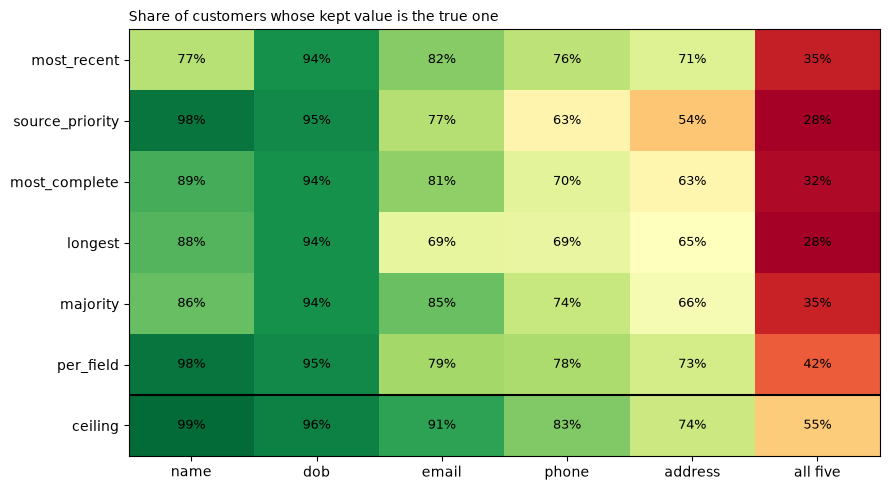

In [7]:
rules = list(r["acc"])
grid = [[r["acc"][k][f] for f in FIELDS] + [r["whole"][k]] for k in rules]
grid.append([r["ceiling"][f] for f in FIELDS] + [r["oracle_whole"]])
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(grid, cmap="RdYlGn", vmin=0.3, vmax=1, aspect="auto")
ax.set_xticks(range(len(FIELDS) + 1), FIELDS + ["all five"])
ax.set_yticks(range(len(rules) + 1), rules + ["ceiling"])
for i, row in enumerate(grid):
    for j, v in enumerate(row):
        ax.text(j, i, f"{100 * v:.0f}%", ha="center", va="center", fontsize=9)
ax.axhline(len(rules) - 0.5, color="black", lw=1.5)
ax.set_title("Share of customers whose kept value is the true one", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- No generic rule-set wins every field: priority wins name, recency wins address, majority wins email.
- The five generic rule-sets agree on the whole golden record for 119 of 364 customers.
- A declared rule per field gets 42.0% of customers fully right; the best generic one 35.2%.
- `updated_at` is a row timestamp; a sync that re-stamps a copied value makes it look fresh and wins the vote.
- 44.8% of customers have a true value no system holds: that half needs a fresh capture, not a rule.

## 7. Try your own

In [8]:
# world = make_world(seed=1)            # another fictional population
# c = world[0]
# for k, rule in RULES.items():
#     print(k, golden(c["records"], rule))
# print("truth", c["truth"])

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version resolves your
own cluster pasted as CSV: `pip install -r requirements.txt && streamlit run app.py`.